In [9]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import pandas as pd
import numpy as np
from sksurv.util import Surv
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.metrics import (concordance_index_censored, integrated_brier_score)
from sksurv.linear_model import CoxPHSurvivalAnalysis

from functions.preproc import *
from functions.ucphm import *

IBS time grid is hardcoded to 2/5/10y inside the function, not passed as an argument.

In [10]:
def univariate_cox_analysis(data_x, data_y, groups, n_splits):

    univariate_results = []
    # need event flags for the stratified split
    event_indicator = [y[0] for y in data_y]
    # grouped CV so patients don't leak across folds
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=12)

    print(f"Starting univariate analysis of {len(data_x.columns)} features...")
    print(f"Using {n_splits}-fold stratified group cross-validation")
    print("-" * 60)

    for i, feature in enumerate(data_x.columns):
        print(f"[{i+1}/{len(data_x.columns)}] Analyzing: {feature}")

        fold_results = {
            "cindex_scores": [],
            "coefficients": [],
            "brier_scores": [],
        }

        # one univariate Cox per fold
        for fold, (train_index, test_index) in enumerate(sgkf.split(data_x, event_indicator, groups)):
            try:
                x_train_single = data_x[feature].iloc[train_index].values.reshape(-1, 1)
                x_test_single = data_x[feature].iloc[test_index].values.reshape(-1, 1)

                y_train_surv = [data_y[i] for i in train_index]
                y_test_surv = [data_y[i] for i in test_index]

                event_train = [e for e, t in y_train_surv]
                time_train = [t for e, t in y_train_surv]
                event_test = [e for e, t in y_test_surv]
                time_test = [t for e, t in y_test_surv]

                # can't score Brier with a single distinct time in the fold
                if np.min(time_test) == np.max(time_test):
                    print(f"     Skipping Brier score: single time point in fold {fold}")
                    continue

                y_train = Surv.from_arrays(event=event_train, time=time_train)
                y_test = Surv.from_arrays(event=event_test, time=time_test)

                cox_model = CoxPHSurvivalAnalysis()
                cox_model.fit(x_train_single, y_train)

                # log-hazard ratio
                fold_results["coefficients"].append(cox_model.coef_[0])

                risk_scores = cox_model.predict(x_test_single)
                cindex = concordance_index_censored(event_test, time_test, risk_scores)[0]
                fold_results["cindex_scores"].append(cindex)

                # IBS at 2/5/10y
                surv_funcs = cox_model.predict_survival_function(x_test_single)
                times = np.array([2*365, 5*365, 10*365])

                surv_preds = np.asarray([[fn(t) for t in times] for fn in surv_funcs])
                if np.isnan(surv_preds).any():
                    print(f"     Skipping Brier score: NaNs in survival predictions in fold {fold}")
                    continue

                ibs = integrated_brier_score(y_train, y_test, surv_preds, times)
                fold_results["brier_scores"].append(ibs)

            except Exception as e:
                print(f"     Warning: Model fitting failed in fold {fold}: {e}")
                continue

        # only aggregate if at least one fold actually worked
        if fold_results["cindex_scores"]:
            mean_cindex = np.mean(fold_results["cindex_scores"])
            std_cindex = np.std(fold_results["cindex_scores"])

            mean_brier = np.mean(fold_results["brier_scores"]) if fold_results["brier_scores"] else np.nan
            std_brier = np.std(fold_results["brier_scores"]) if fold_results["brier_scores"] else np.nan

            mean_coef = np.mean(fold_results["coefficients"])
            std_coef = np.std(fold_results["coefficients"])

            # HR + 95% CI from the fold coefficients
            hr = np.exp(mean_coef)
            hr_lower = np.exp(mean_coef - 1.96 * std_coef)
            hr_upper = np.exp(mean_coef + 1.96 * std_coef)

            # Wald test on mean_coef: se -> z -> two-sided p
            se_mean_coef = std_coef / np.sqrt(len(fold_results["coefficients"]))
            wald_z = mean_coef / se_mean_coef
            p_value = 2 * norm.sf(abs(wald_z)) # sf = survival fn, i.e. 1 - cdf

            univariate_results.append({
                "Feature": feature,
                "C_Index_Mean": mean_cindex,
                "C_Index_Std": std_cindex,
                "Integrated_Brier_Score": mean_brier,
                "Brier_Score_Std": std_brier,
                "Coefficient_Mean": mean_coef,
                "Coefficient_Std": std_coef,
                "Hazard_Ratio": hr,
                "HR_95_CI_Lower": hr_lower,
                "HR_95_CI_Upper": hr_upper,
                "P_Value_of_HR": p_value, 
                "N_Successful_Folds": len(fold_results["cindex_scores"]),
            })

            print(f"     C-index: {mean_cindex:.4f} ± {std_cindex:.4f}")
            print(f"     Integrated Brier score: {mean_brier:.4f} ± {std_brier:.4f}")
            print(f"     HR: {hr:.4f} (95% CI: {hr_lower:.4f}–{hr_upper:.4f}), P-value: {p_value:.4f}")
        else:
            print(f"     Failed to fit any models for {feature}")

    results_df = pd.DataFrame(univariate_results)
    return results_df

Dataset's already cleaned; only the numerical NaNs still need imputing.

In [11]:
dataset = pd.read_csv("data_treated_ultrasound.csv")

In [12]:
feature_columns = ['Ultrasound scan_0.0', 'Ultrasound scan_2.0', 'Ultrasound scan_3.0', 'Ultrasound scan_4.0', 'Ultrasound scan_5.0', 'Pathological size (mm.)', 'Tumour size by imaging or clinical examination']

In [13]:
survival_dataset = dataset.drop('Unnamed: 0', axis=1)

In [14]:
data_y = Surv.from_arrays(survival_dataset['Regional LN recurrence'], survival_dataset['Survival days'])
data_x = survival_dataset[feature_columns]
groups = survival_dataset['PERSON_ID']

In [15]:
univariate_results = univariate_cox_analysis(data_x, data_y, groups, 4)
univariate_results

Starting univariate analysis of 7 features...
Using 4-fold stratified group cross-validation
------------------------------------------------------------
[1/7] Analyzing: Ultrasound scan_0.0
     C-index: 0.5751 ± 0.0423
     Integrated Brier score: 0.0178 ± 0.0084
     HR: 2.0777 (95% CI: 1.7295–2.4960), P-value: 0.0000
[2/7] Analyzing: Ultrasound scan_2.0
     C-index: 0.5021 ± 0.0014
     Integrated Brier score: 0.0175 ± 0.0085
     HR: 0.0000 (95% CI: 0.0000–0.0000), P-value: 0.0000
[3/7] Analyzing: Ultrasound scan_3.0
     C-index: 0.5027 ± 0.0014
     Integrated Brier score: 0.0175 ± 0.0085
     HR: 0.0000 (95% CI: 0.0000–0.0000), P-value: 0.0000
[4/7] Analyzing: Ultrasound scan_4.0
     C-index: 0.5080 ± 0.0009
     Integrated Brier score: 0.0175 ± 0.0085
     HR: 0.0000 (95% CI: 0.0000–0.0000), P-value: 0.0000
[5/7] Analyzing: Ultrasound scan_5.0
     C-index: 0.5624 ± 0.0429
     Integrated Brier score: 0.0176 ± 0.0085
     HR: 0.6133 (95% CI: 0.5213–0.7215), P-value: 0.0000
[

,Feature,C_Index_Mean,C_Index_Std,Integrated_Brier_Score,Brier_Score_Std,Coefficient_Mean,Coefficient_Std,Hazard_Ratio,HR_95_CI_Lower,HR_95_CI_Upper,P_Value_of_HR,N_Successful_Folds
0,Ultrasound scan_0.0,0.575129,0.042285,0.017763,0.008415,0.731258,0.093595,2.077692e+00,1.729465e+00,2.496035e+00,4.838344e-55,4
1,Ultrasound scan_2.0,0.502058,0.001382,0.017474,0.008474,-14.257239,0.434302,6.429242e-07,2.744570e-07,1.506070e-06,0.000000e+00,4
2,Ultrasound scan_3.0,0.502670,0.001351,0.017465,0.008475,-14.759214,0.433667,3.891837e-07,1.663449e-07,9.105415e-07,0.000000e+00,4
3,Ultrasound scan_4.0,0.507965,0.000866,0.017473,0.008466,-16.030175,0.001775,1.091902e-07,1.088110e-07,1.095707e-07,0.000000e+00,4
4,Ultrasound scan_5.0,0.562435,0.042927,0.017640,0.008452,-0.488941,0.082909,6.132753e-01,5.212934e-01,7.214873e-01,4.156429e-32,4
5,Pathological size (mm.),0.557766,0.068296,0.017435,0.008508,0.013760,0.002835,1.013855e+00,1.008237e+00,1.019505e+00,2.816470e-22,4
6,Tumour size by imaging or clinical examination,0.568111,0.109311,0.017445,0.008477,0.009849,0.005344,1.009898e+00,9.993755e-01,1.020531e+00,2.276246e-04,4


In [ ]:
univariate_results.to_csv('ucphm_diagnostic_365.csv')

In [ ]:
# I have very low data of these
highlight_features = []
# in the hazard ration these are giving a very high error not sure why
new_uni = univariate_results[
    ~univariate_results['Feature'].isin(['Classification with respect to other lesions_2.0', 'Disease extent_2.0', 'Grade at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_2.0'])
]

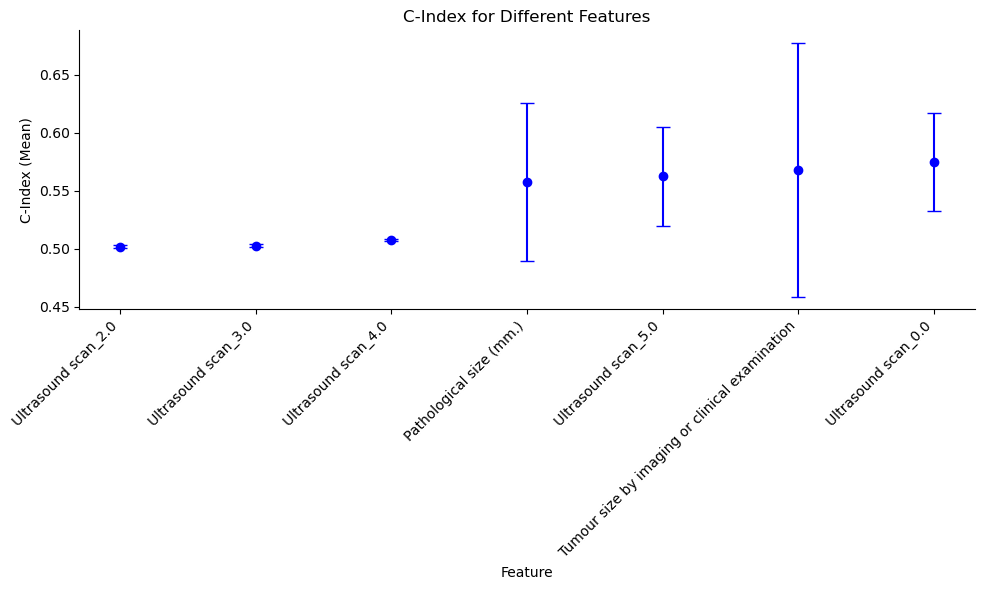

In [16]:
plot_cindex(univariate_results, 'ci_ucphm_di.png', highlight_features=[], highlight_color='red', default_color='blue')

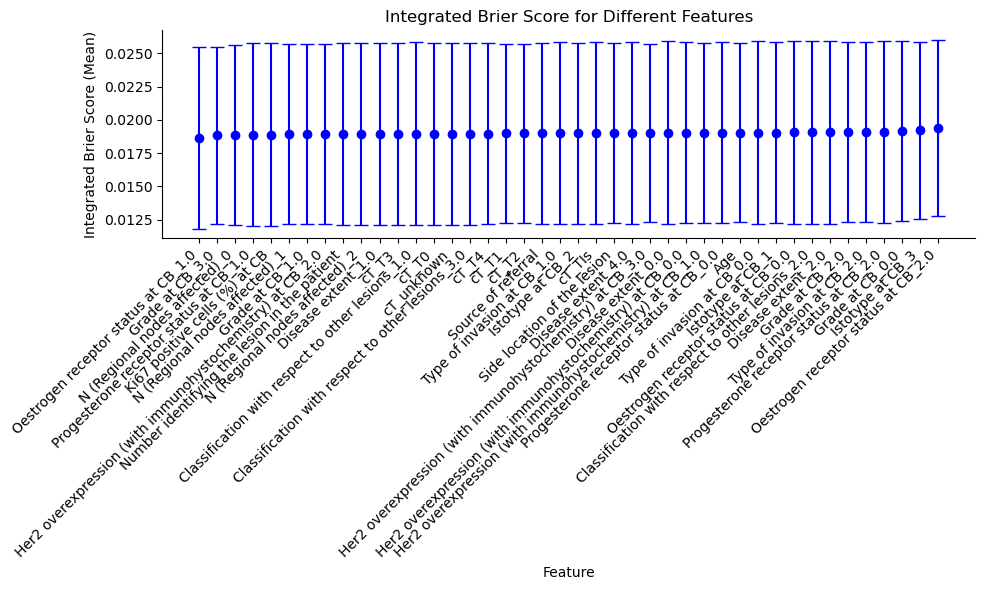

In [ ]:
plot_brier(univariate_results, 'brier_ucphm_di_365.png', highlight_features=[], highlight_color='red', default_color='blue')

In [ ]:
non_significant_features = univariate_results[univariate_results['P_Value_of_HR'] >= 0.05]
non_significant_features = non_significant_features['Feature'].to_list()
highlight_features = highlight_features + non_significant_features

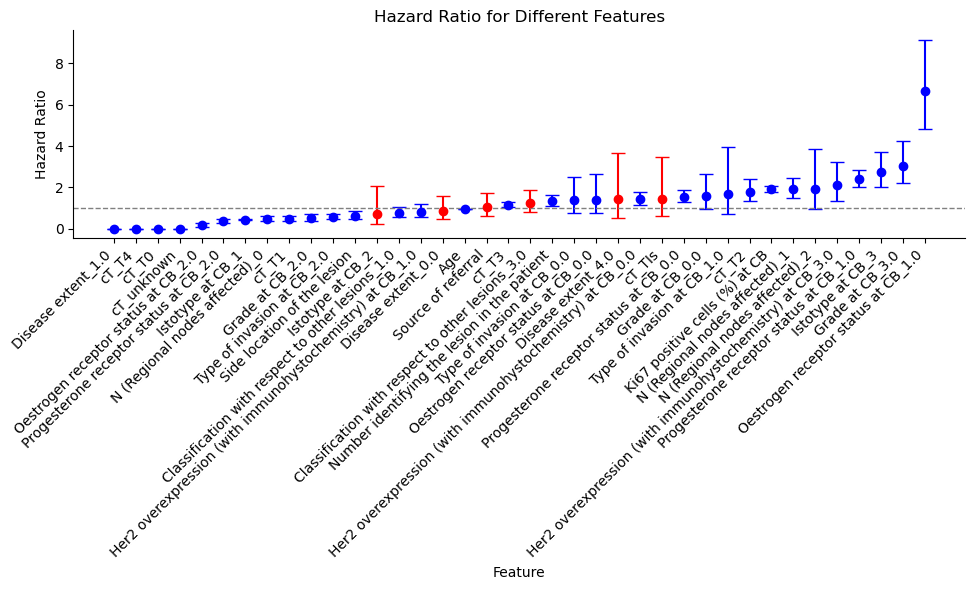

In [ ]:
plot_hazard(new_uni, 'hr_ucphm_di.png', highlight_features=highlight_features, highlight_color='red', default_color='blue')

In [ ]:
import pandas as pd
univariate_results = pd.read_csv('ucphm_diagnostic_365.csv')
mean_val = univariate_results.iloc[:, 2].mean()
std_val = univariate_results.iloc[:, 2].std()
print("Mean:", mean_val)
print("Std:", std_val)
num_significant = (univariate_results['P_Value_of_HR'] < 0.05).sum()
print("Number of significant features:", num_significant)
print("Total number of features:", len(univariate_results))

Mean: 0.5488763659753422
Std: 0.0839996353440264
Number of significant features: 32
Total number of features: 42
